In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import (precision_score,recall_score,f1_score,classification_report,confusion_matrix)
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier


In [5]:
df = pd.read_csv("/kaggle/input/datasets/miadul/irrigation-water-requirement-prediction-dataset/irrigation_prediction.csv")

In [3]:
df.head(5)

,Soil_Type,Soil_pH,Soil_Moisture,Organic_Carbon,Electrical_Conductivity,Temperature_C,Humidity,Rainfall_mm,Sunlight_Hours,Wind_Speed_kmh,Crop_Type,Crop_Growth_Stage,Season,Irrigation_Type,Water_Source,Field_Area_hectare,Mulching_Used,Previous_Irrigation_mm,Region,Irrigation_Need
0,Clay,6.14,36.48,0.42,2.17,21.90,31.19,1167.70,4.01,1.97,Wheat,Vegetative,Rabi,Rainfed,Reservoir,4.73,Yes,1.98,South,Low
1,Silt,6.41,50.56,0.38,0.23,36.50,26.01,831.28,10.72,16.82,Maize,Flowering,Zaid,Canal,Groundwater,12.22,Yes,33.56,Central,Medium
2,Sandy,7.71,40.07,1.09,2.18,41.83,76.41,1844.45,7.75,19.03,Cotton,Harvest,Rabi,Drip,Reservoir,5.52,Yes,34.62,South,Low
3,Clay,5.96,12.75,1.56,0.40,37.22,43.32,306.26,8.90,11.44,Wheat,Sowing,Kharif,Canal,Reservoir,1.43,Yes,84.03,North,Medium
4,Clay,7.76,18.58,0.95,2.52,22.38,86.44,1875.63,10.39,11.26,Cotton,Sowing,Zaid,Canal,River,2.52,No,60.86,South,Medium


In [4]:
df.sample(10)

,Soil_Type,Soil_pH,Soil_Moisture,Organic_Carbon,Electrical_Conductivity,Temperature_C,Humidity,Rainfall_mm,Sunlight_Hours,Wind_Speed_kmh,Crop_Type,Crop_Growth_Stage,Season,Irrigation_Type,Water_Source,Field_Area_hectare,Mulching_Used,Previous_Irrigation_mm,Region,Irrigation_Need
6215,Clay,5.65,14.32,0.80,0.57,30.78,85.73,1340.68,5.76,10.39,Cotton,Harvest,Zaid,Sprinkler,Reservoir,9.25,Yes,12.26,North,Medium
4508,Silt,5.78,63.26,1.59,0.49,26.31,82.18,2236.97,4.87,18.01,Maize,Flowering,Zaid,Rainfed,Reservoir,3.92,Yes,27.14,West,Low
413,Sandy,4.98,25.52,0.80,2.14,36.52,48.72,1748.03,5.69,17.02,Cotton,Vegetative,Rabi,Drip,Rainwater,2.62,No,60.07,South,Medium
2770,Clay,6.51,48.38,1.11,0.12,37.31,57.80,1069.30,7.16,8.97,Maize,Vegetative,Rabi,Sprinkler,River,5.95,Yes,84.13,North,Low
3922,Loamy,6.89,46.91,1.01,1.59,33.41,76.14,896.70,4.14,9.46,Maize,Harvest,Zaid,Rainfed,River,14.40,No,34.56,North,Low
6991,Silt,5.33,29.79,1.07,2.20,30.73,55.76,675.85,5.06,14.31,Cotton,Flowering,Kharif,Canal,Groundwater,11.47,No,84.92,West,Medium
6410,Sandy,5.21,59.35,1.39,0.41,39.59,31.66,1684.04,5.69,19.20,Maize,Vegetative,Rabi,Canal,Reservoir,13.97,No,69.78,North,Medium
5187,Silt,7.77,20.71,0.76,3.05,25.01,27.91,1040.37,7.74,9.65,Rice,Harvest,Rabi,Sprinkler,Groundwater,7.26,Yes,68.82,South,Low
8782,Silt,6.01,55.65,0.94,2.58,40.35,30.80,1215.17,10.94,2.22,Maize,Sowing,Rabi,Drip,River,5.72,Yes,29.86,Central,Low
577,Loamy,8.14,45.63,0.39,1.10,15.80,74.91,1589.75,6.72,11.86,Rice,Vegetative,Zaid,Canal,Rainwater,3.90,Yes,92.80,South,Low


In [5]:
df.shape

(10000, 20)

In [6]:
df.describe()

,Soil_pH,Soil_Moisture,Organic_Carbon,Electrical_Conductivity,Temperature_C,Humidity,Rainfall_mm,Sunlight_Hours,Wind_Speed_kmh,Field_Area_hectare,Previous_Irrigation_mm
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,6.487857,36.969207,0.944731,1.791963,26.991423,60.080339,1252.499420,7.518538,10.163545,7.598024,59.864122
std,0.979963,16.430845,0.372406,0.984202,8.664074,20.187973,715.582201,2.016077,5.670923,4.233919,34.483722
min,4.800000,8.000000,0.300000,0.100000,12.000000,25.000000,0.380000,4.000000,0.500000,0.300000,0.020000
25%,5.640000,22.860000,0.620000,0.940000,19.460000,42.855000,634.155000,5.760000,5.160000,3.950000,30.160000
50%,6.470000,37.240000,0.950000,1.780000,27.090000,60.040000,1250.335000,7.560000,10.190000,7.540000,59.630000
75%,7.350000,50.940000,1.260000,2.650000,34.500000,77.705000,1880.265000,9.260000,15.100000,11.202500,90.030000
max,8.200000,65.000000,1.600000,3.500000,42.000000,95.000000,2499.690000,11.000000,20.000000,15.000000,119.990000


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Soil_Type                10000 non-null  object 
 1   Soil_pH                  10000 non-null  float64
 2   Soil_Moisture            10000 non-null  float64
 3   Organic_Carbon           10000 non-null  float64
 4   Electrical_Conductivity  10000 non-null  float64
 5   Temperature_C            10000 non-null  float64
 6   Humidity                 10000 non-null  float64
 7   Rainfall_mm              10000 non-null  float64
 8   Sunlight_Hours           10000 non-null  float64
 9   Wind_Speed_kmh           10000 non-null  float64
 10  Crop_Type                10000 non-null  object 
 11  Crop_Growth_Stage        10000 non-null  object 
 12  Season                   10000 non-null  object 
 13  Irrigation_Type          10000 non-null  object 
 14  Water_Source           

In [8]:
df.isnull().sum()

Soil_Type                  0
Soil_pH                    0
Soil_Moisture              0
Organic_Carbon             0
Electrical_Conductivity    0
Temperature_C              0
Humidity                   0
Rainfall_mm                0
Sunlight_Hours             0
Wind_Speed_kmh             0
Crop_Type                  0
Crop_Growth_Stage          0
Season                     0
Irrigation_Type            0
Water_Source               0
Field_Area_hectare         0
Mulching_Used              0
Previous_Irrigation_mm     0
Region                     0
Irrigation_Need            0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:

# Check the distribution of the target variable
print("Irrigation Need Distribution:")
print(df["Irrigation_Need"].value_counts())

print("\nPercentage Distribution:")
print((df["Irrigation_Need"].value_counts(normalize=True) * 100).round(2))


Irrigation Need Distribution:
Irrigation_Need
Low       5864
Medium    3800
High       336
Name: count, dtype: int64

Percentage Distribution:
Irrigation_Need
Low       58.64
Medium    38.00
High       3.36
Name: proportion, dtype: float64


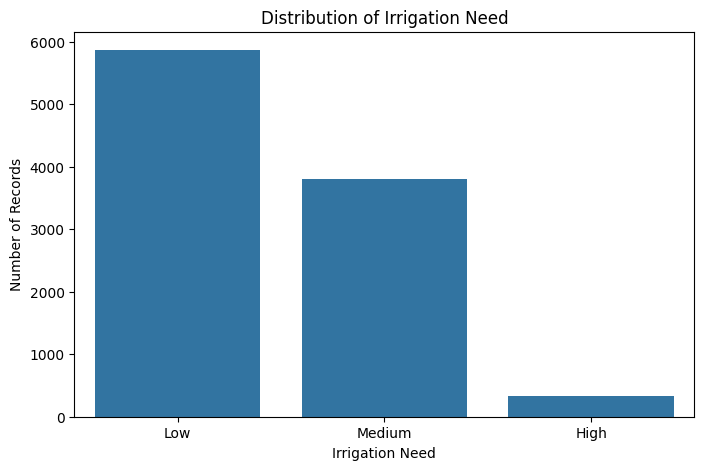

In [6]:


plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Irrigation_Need",
    order=df["Irrigation_Need"].value_counts().index
)

plt.title("Distribution of Irrigation Need")
plt.xlabel("Irrigation Need")
plt.ylabel("Number of Records")
plt.show()


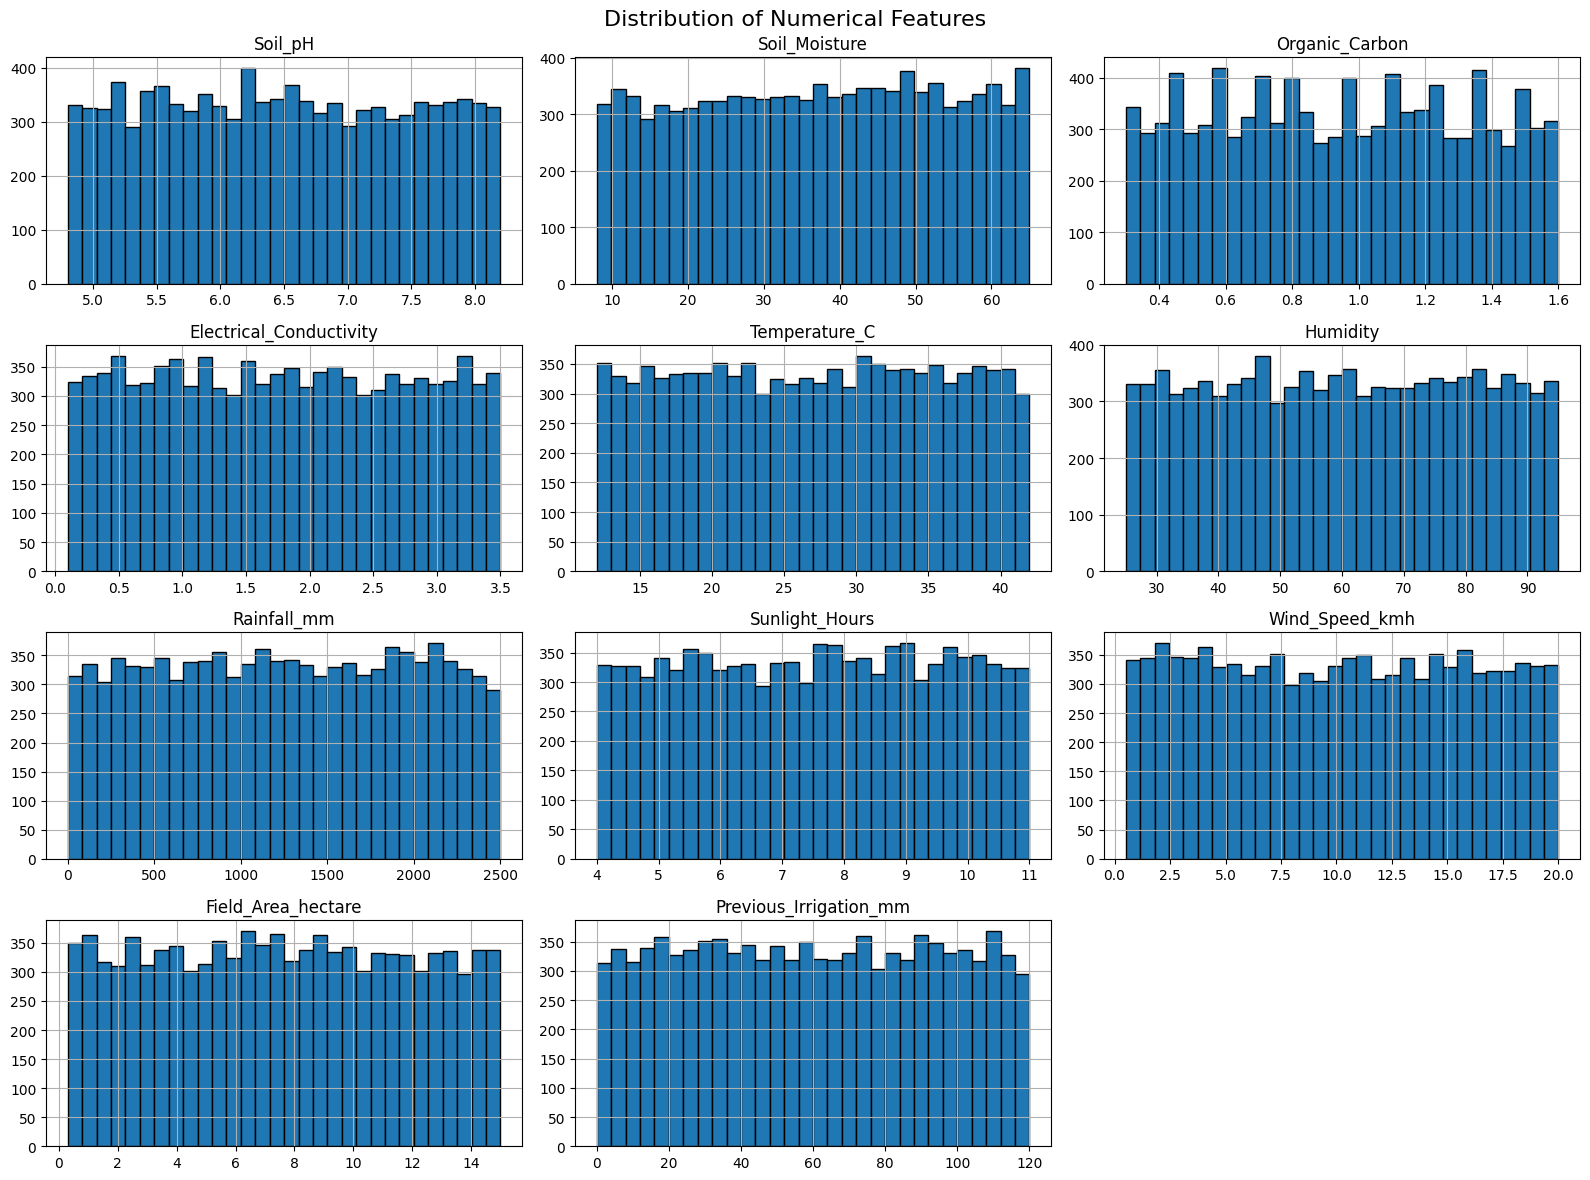

In [7]:

# Select numerical features, excluding the target if it is encoded numerically
numerical_cols = df.select_dtypes(include=["int64", "float64"]).columns

df[numerical_cols].hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()


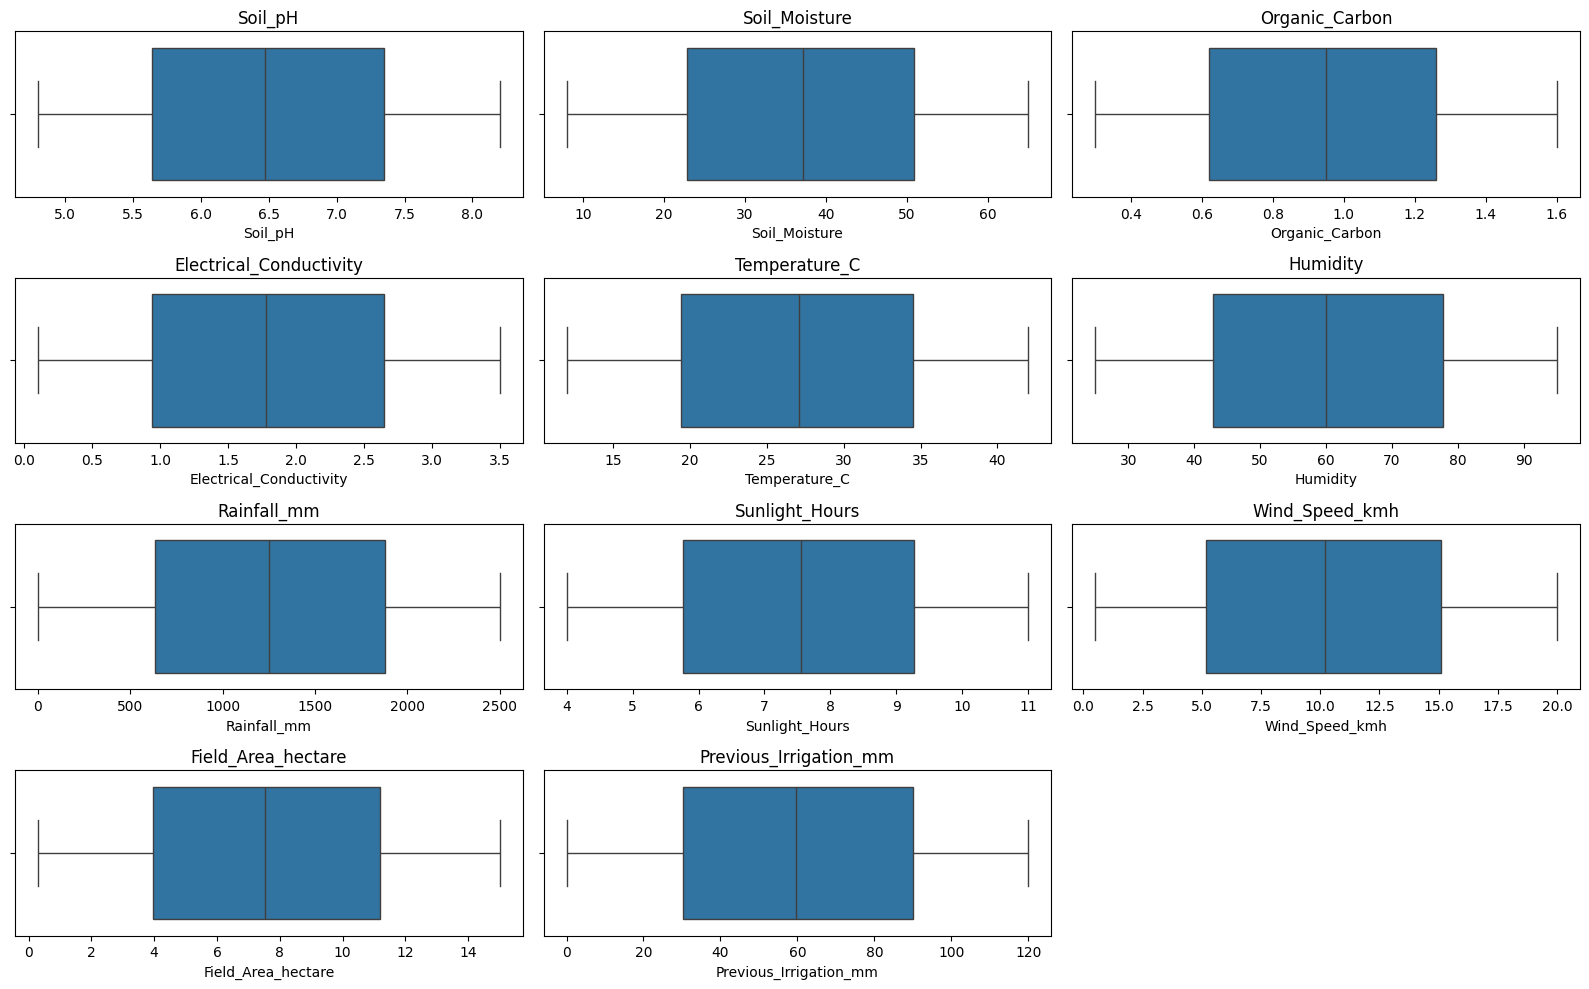

In [14]:

plt.figure(figsize=(16, 10))

for i, col in enumerate(numerical_cols, 1):
    plt.subplot(4, 3, i)
    sns.boxplot(x=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()


In [8]:

categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns

print("Categorical Columns:", list(categorical_cols))

for col in categorical_cols:
    print(f"\n{col}")
    print(df[col].value_counts())


Categorical Columns: ['Soil_Type', 'Crop_Type', 'Crop_Growth_Stage', 'Season', 'Irrigation_Type', 'Water_Source', 'Mulching_Used', 'Region', 'Irrigation_Need']

Soil_Type
Soil_Type
Sandy    2536
Silt     2501
Loamy    2486
Clay     2477
Name: count, dtype: int64

Crop_Type
Crop_Type
Rice         1711
Maize        1694
Sugarcane    1678
Potato       1663
Wheat        1659
Cotton       1595
Name: count, dtype: int64

Crop_Growth_Stage
Crop_Growth_Stage
Harvest       2581
Vegetative    2521
Flowering     2465
Sowing        2433
Name: count, dtype: int64

Season
Season
Rabi      3383
Kharif    3362
Zaid      3255
Name: count, dtype: int64

Irrigation_Type
Irrigation_Type
Sprinkler    2527
Rainfed      2511
Drip         2495
Canal        2467
Name: count, dtype: int64

Water_Source
Water_Source
River          2528
Reservoir      2513
Rainwater      2497
Groundwater    2462
Name: count, dtype: int64

Mulching_Used
Mulching_Used
No     5013
Yes    4987
Name: count, dtype: int64

Region
Region

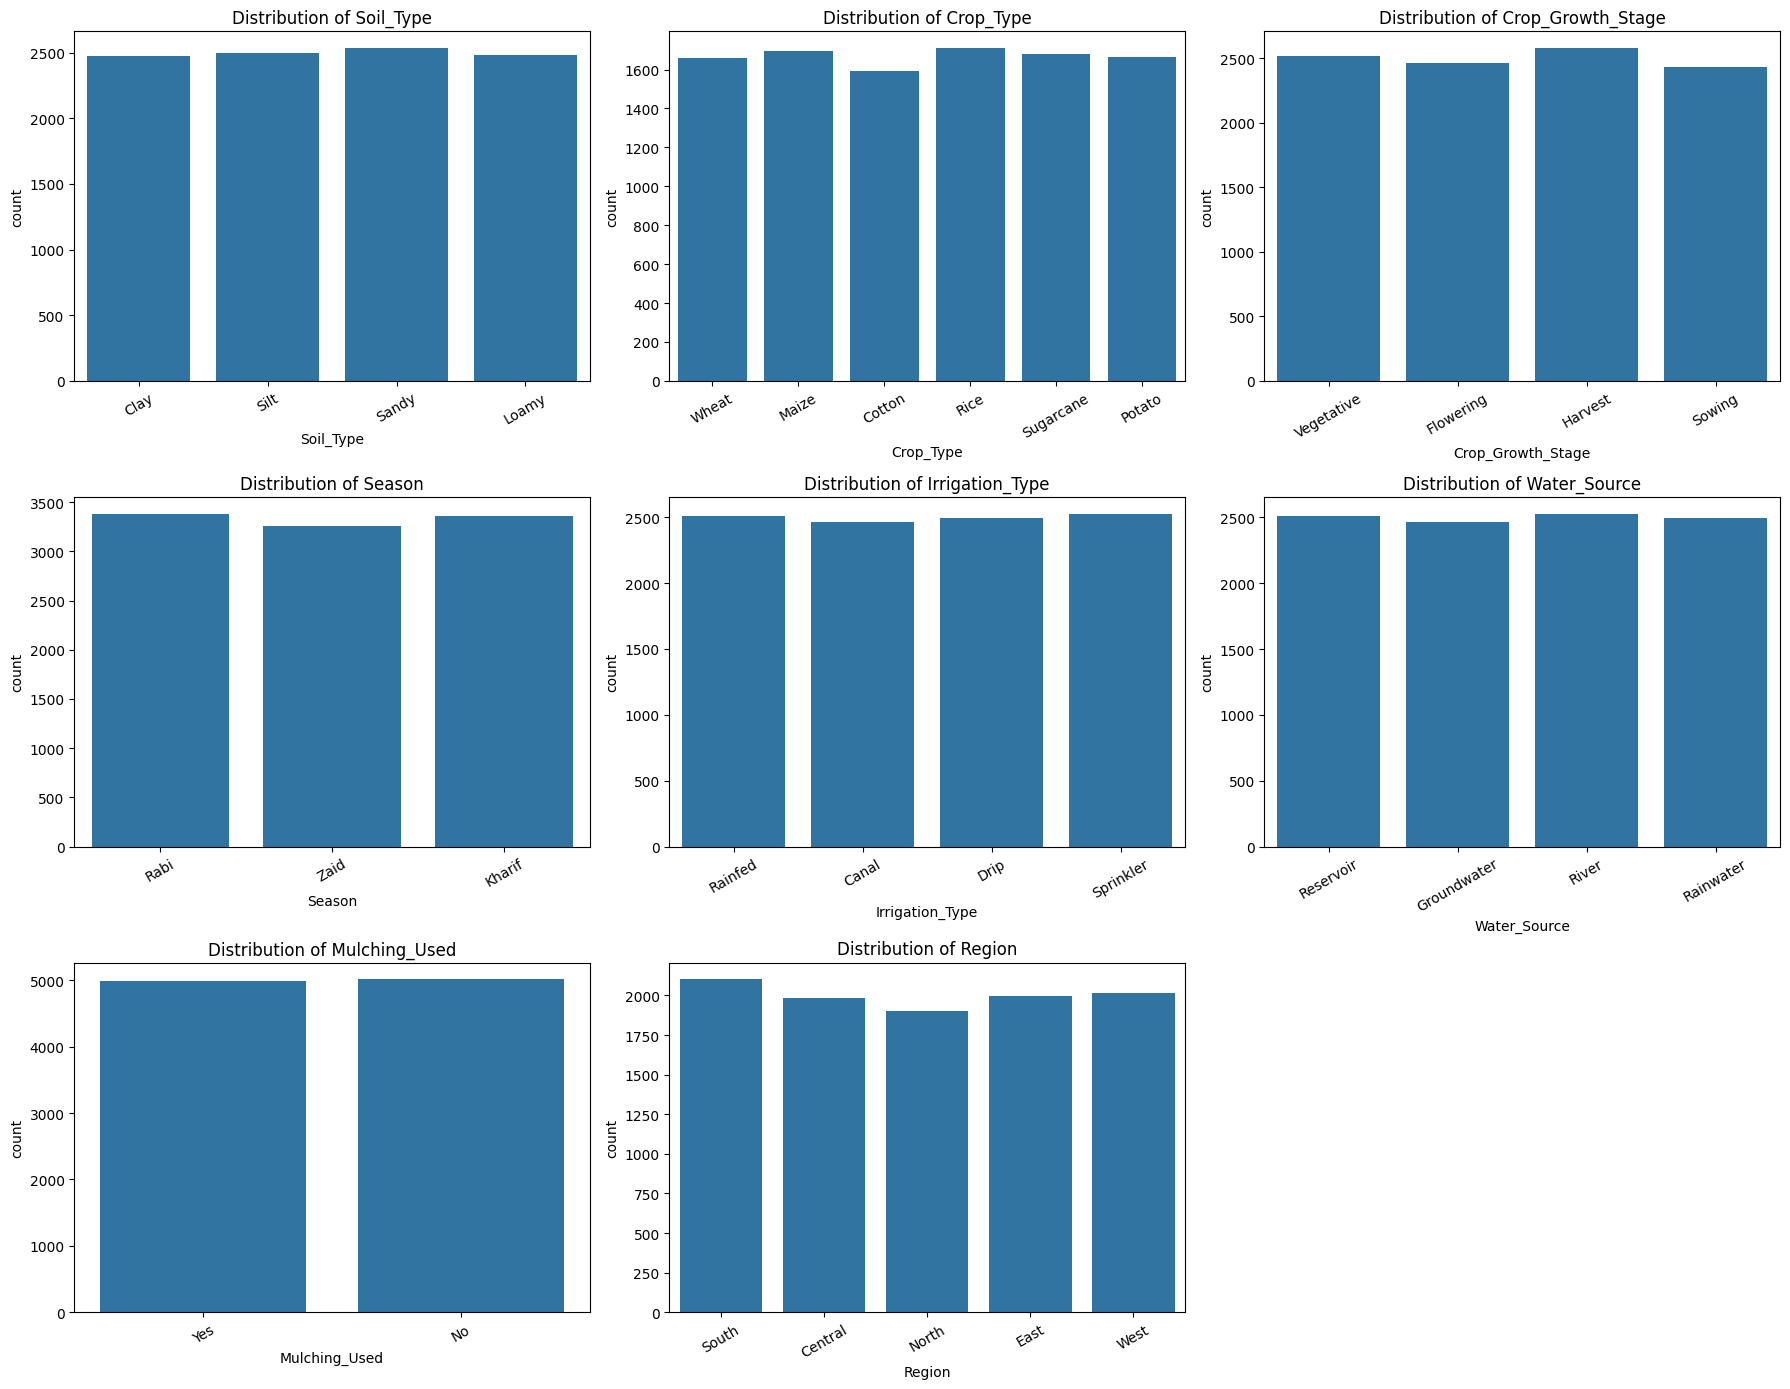

In [16]:
categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns.drop("Irrigation_Need", errors="ignore")

fig, axes = plt.subplots(3, 3, figsize=(18, 14))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    sns.countplot(data=df, x=col, ax=axes[i])
    axes[i].set_title(f"Distribution of {col}")
    axes[i].tick_params(axis="x", rotation=30)

for j in range(len(categorical_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

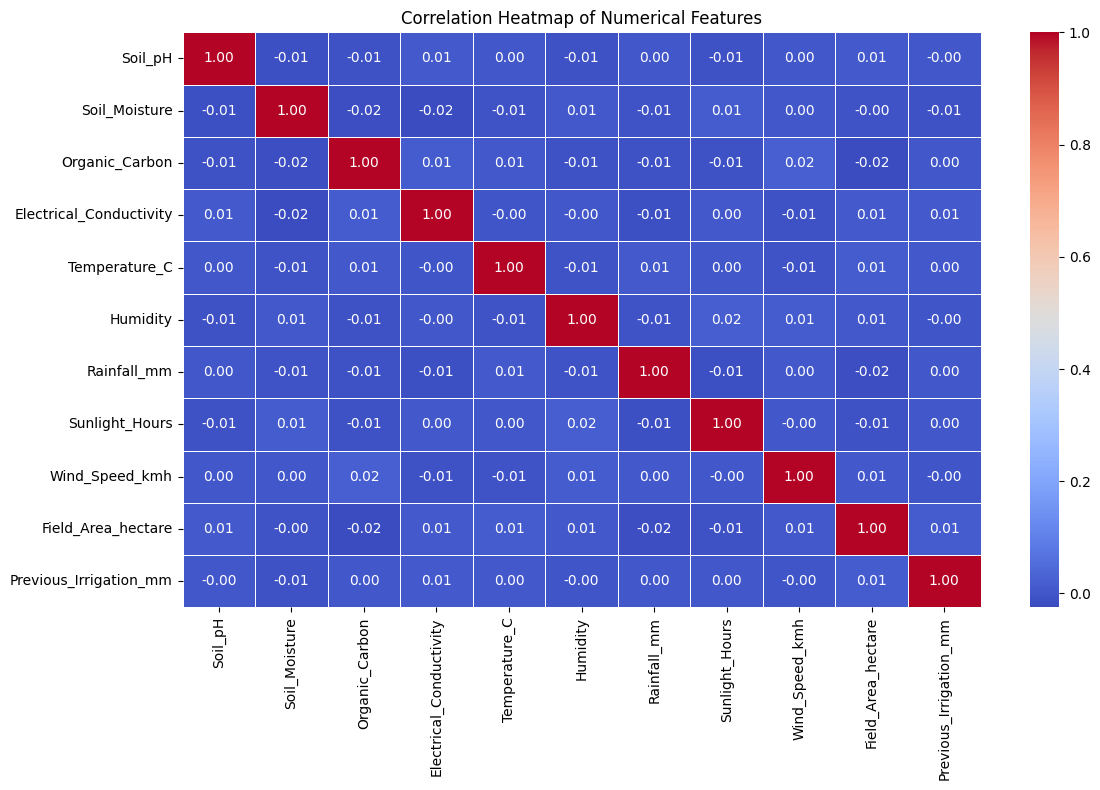

In [17]:
plt.figure(figsize=(12, 8))

correlation = df.select_dtypes(include=["number"]).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

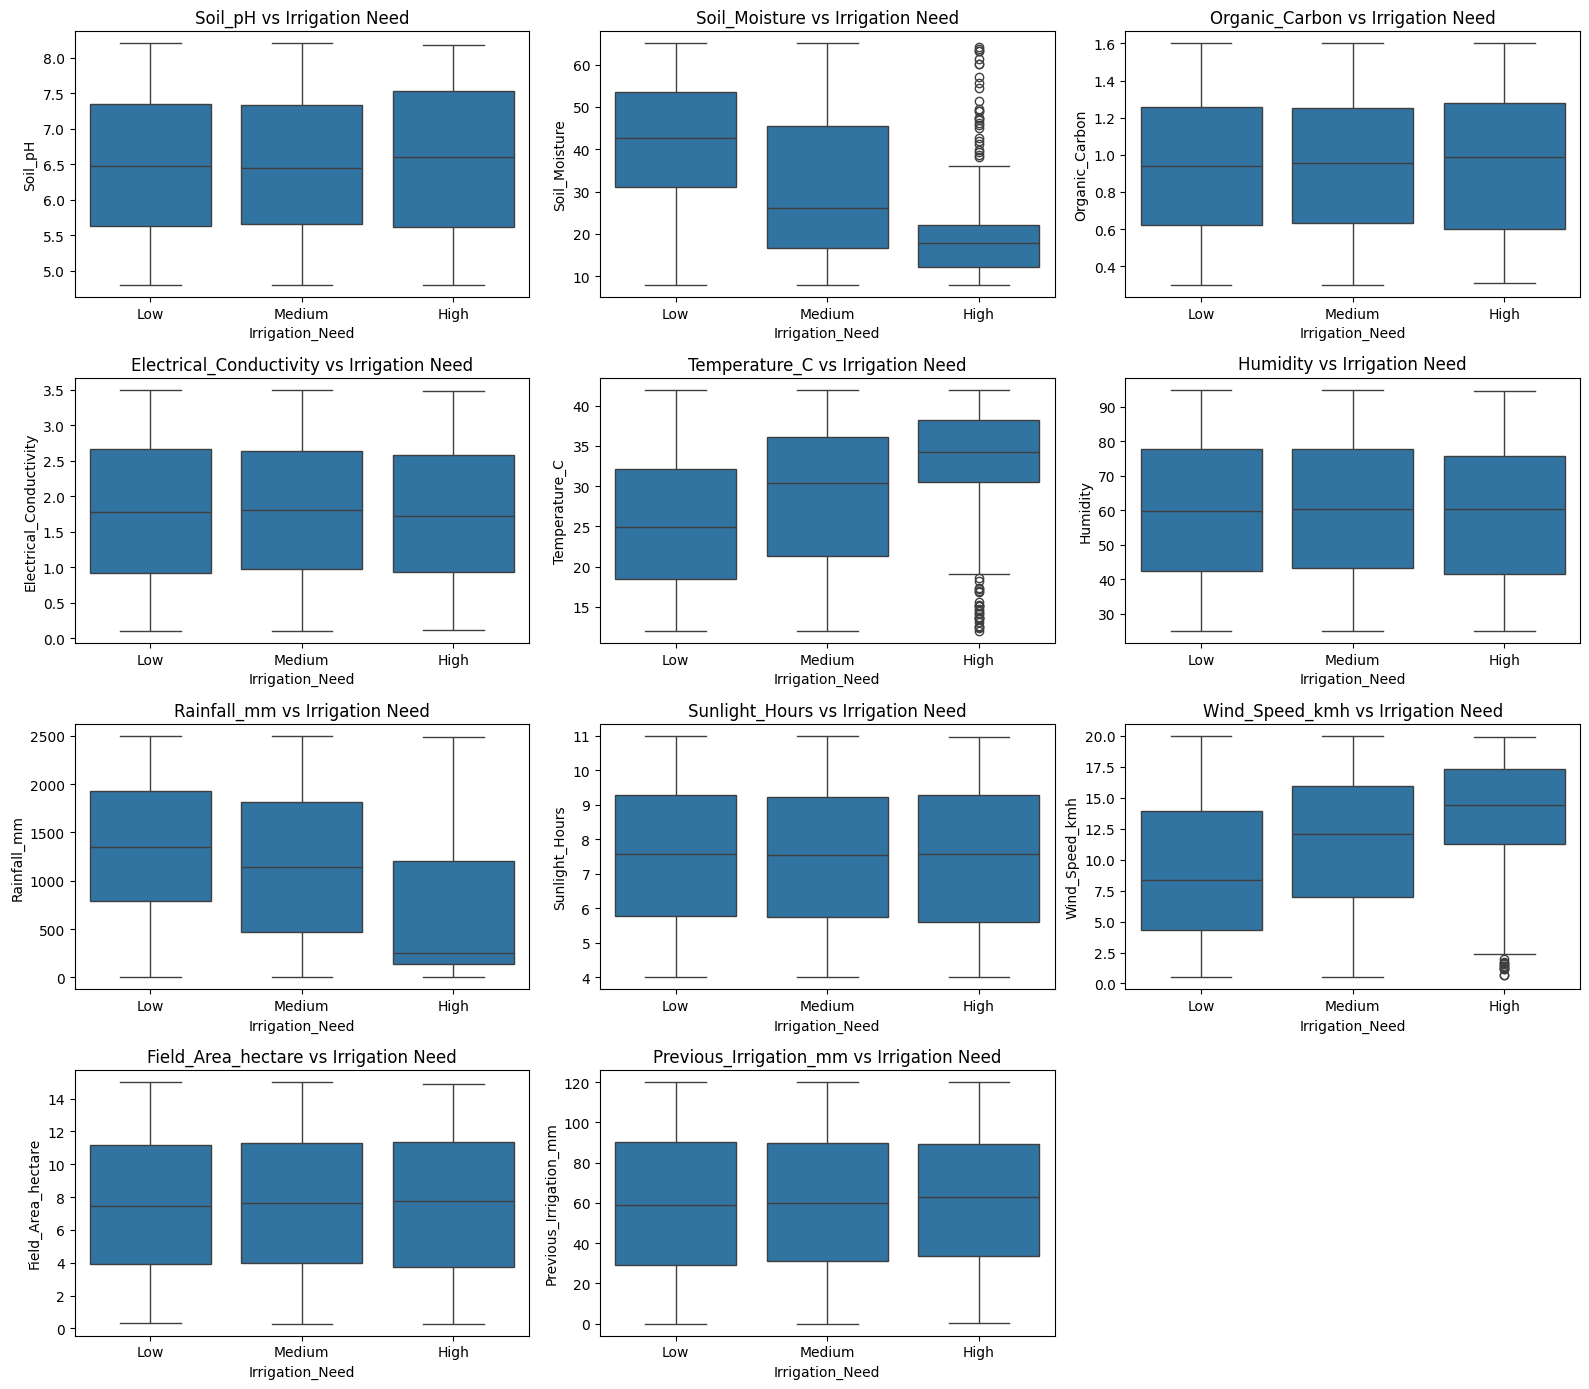

In [18]:
numerical_cols = df.select_dtypes(include=["number"]).columns

fig, axes = plt.subplots(4, 3, figsize=(16, 14))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.boxplot(data=df, x="Irrigation_Need", y=col, ax=axes[i])
    axes[i].set_title(f"{col} vs Irrigation Need")

for j in range(len(numerical_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

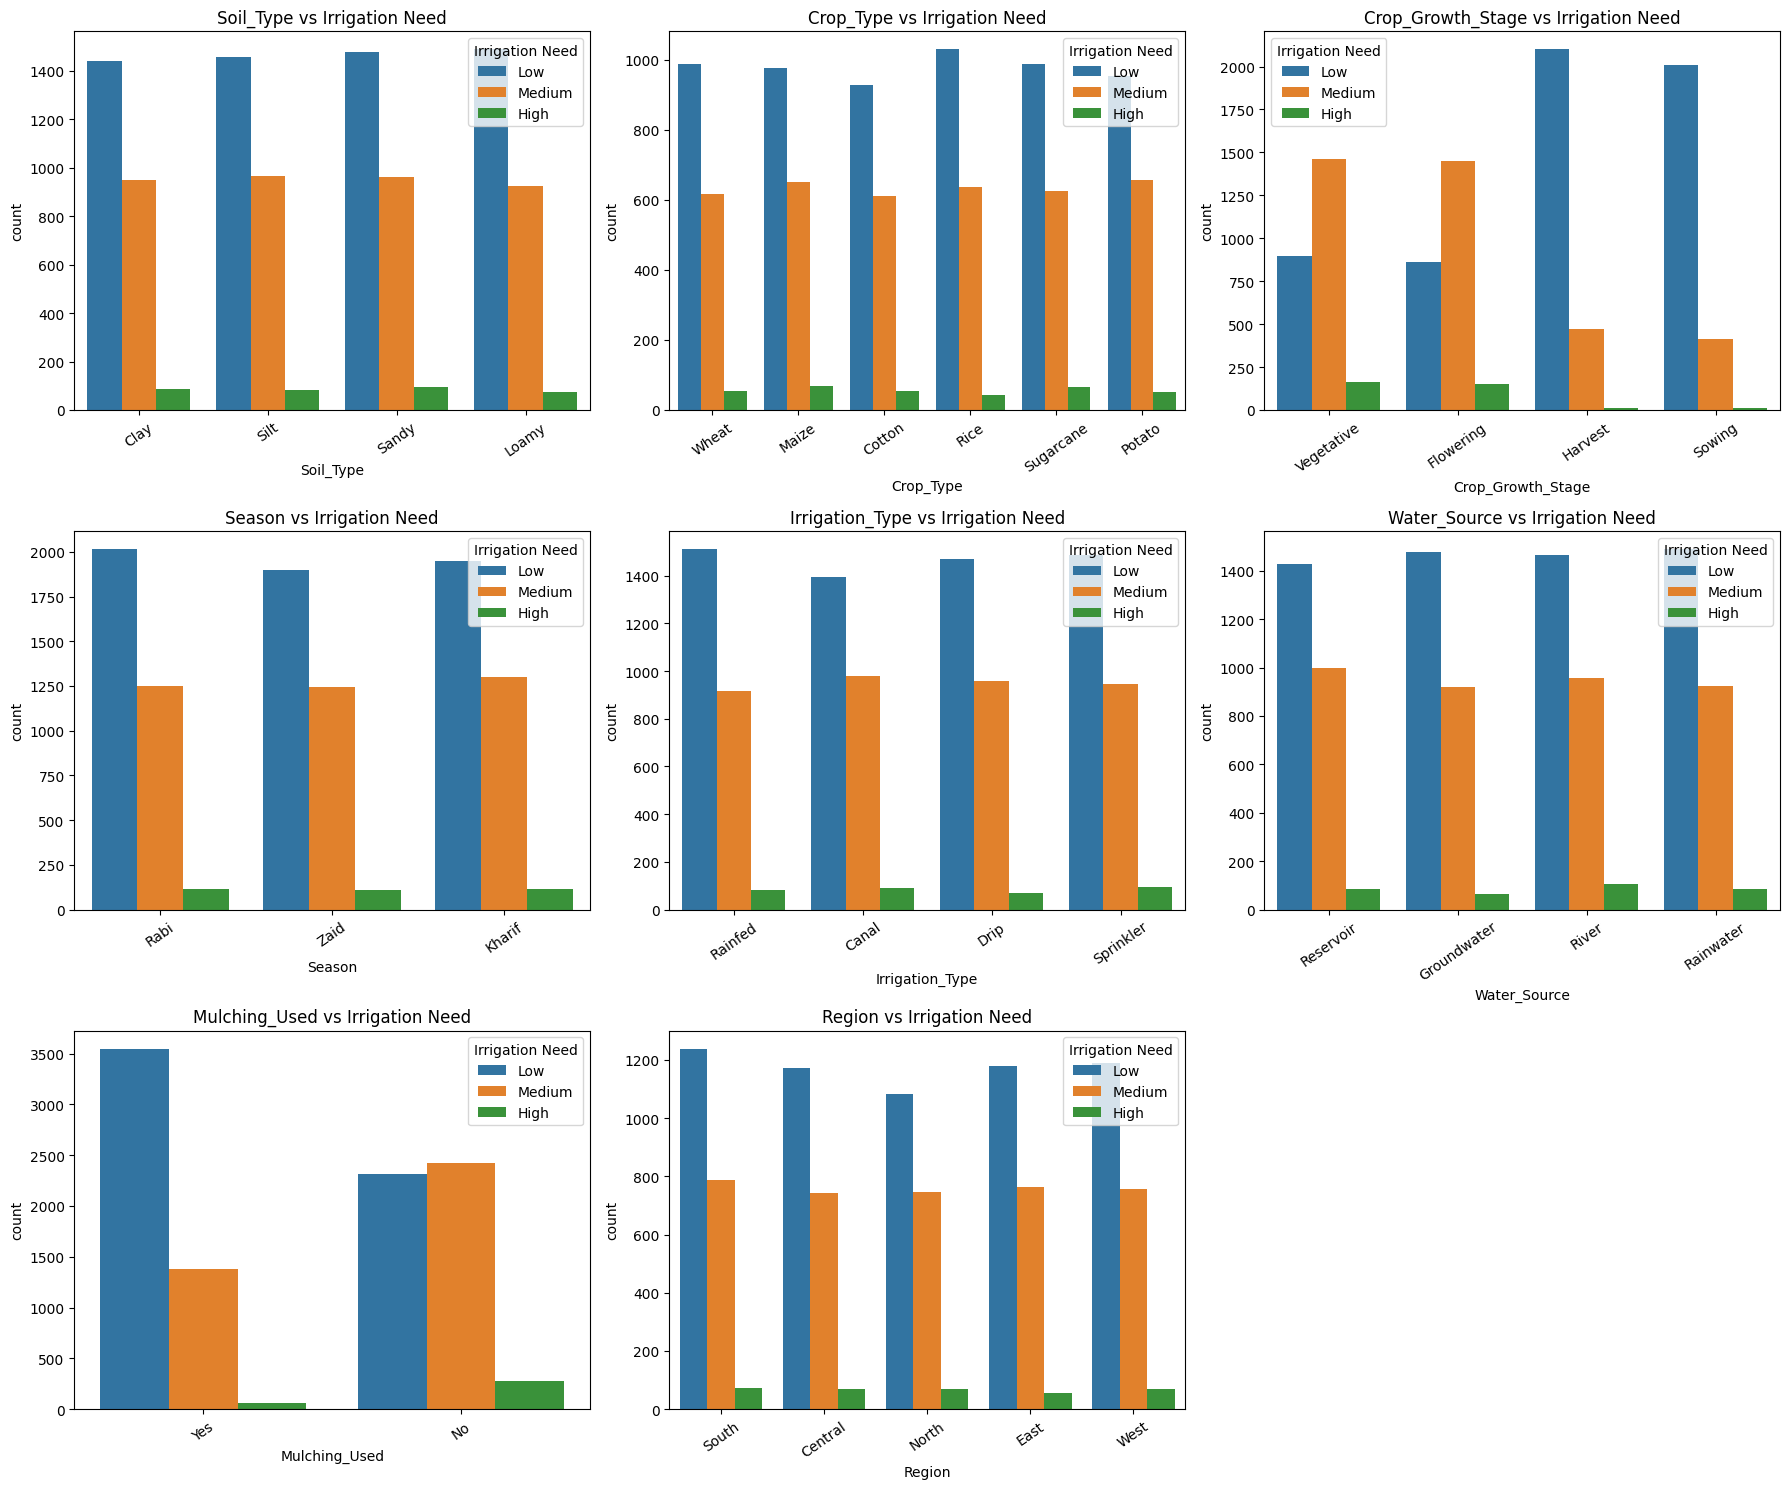

In [9]:
categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns.drop("Irrigation_Need", errors="ignore")

fig, axes = plt.subplots(3, 3, figsize=(18, 15))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    sns.countplot(
        data=df,
        x=col,
        hue="Irrigation_Need",
        ax=axes[i]
    )
    axes[i].set_title(f"{col} vs Irrigation Need")
    axes[i].tick_params(axis="x", rotation=35)
    axes[i].legend(title="Irrigation Need")

for j in range(len(categorical_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

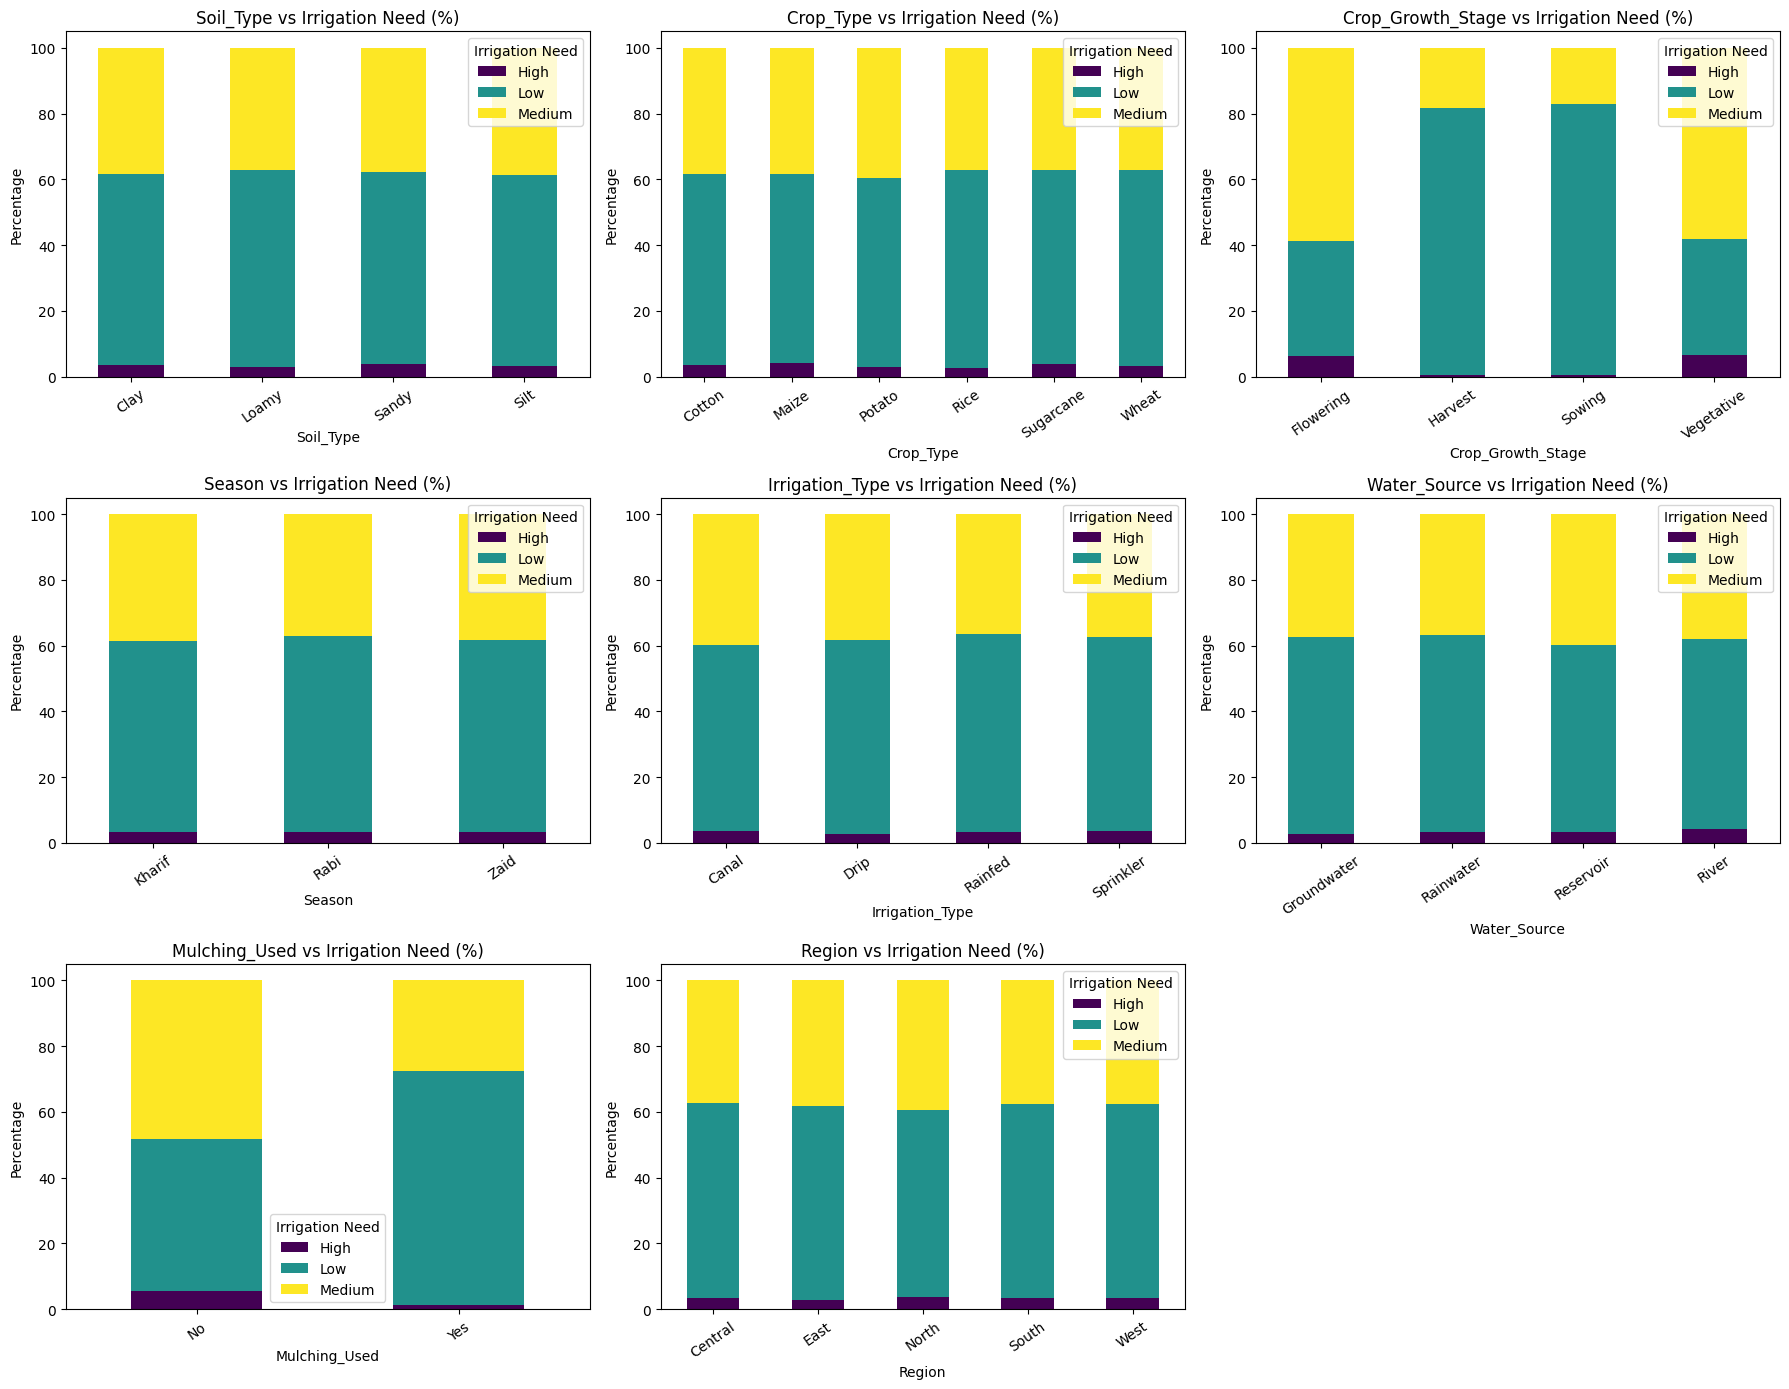

In [20]:
categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns.drop("Irrigation_Need", errors="ignore")

fig, axes = plt.subplots(3, 3, figsize=(18, 14))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    proportions = pd.crosstab(
        df[col],
        df["Irrigation_Need"],
        normalize="index"
    ) * 100

    proportions.plot(
        kind="bar",
        stacked=True,
        ax=axes[i],
        colormap="viridis"
    )

    axes[i].set_title(f"{col} vs Irrigation Need (%)")
    axes[i].set_ylabel("Percentage")
    axes[i].tick_params(axis="x", rotation=35)
    axes[i].legend(title="Irrigation Need")

for j in range(len(categorical_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [21]:


categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns.drop("Irrigation_Need", errors="ignore")

results = []

for col in categorical_cols:
    table = pd.crosstab(df[col], df["Irrigation_Need"])
    chi2, p_value, dof, expected = chi2_contingency(table)

    results.append({
        "Feature": col,
        "Chi2 Statistic": chi2,
        "P-value": p_value
    })

chi_results = pd.DataFrame(results).sort_values("P-value")
chi_results

,Feature,Chi2 Statistic,P-value
2,Crop_Growth_Stage,2291.619193,0.000000e+00
6,Mulching_Used,682.405004,6.571072e-149
5,Water_Source,14.996889,2.028092e-02
4,Irrigation_Type,10.813354,9.431911e-02
1,Crop_Type,11.004056,3.572021e-01
0,Soil_Type,4.205004,6.489558e-01
3,Season,2.300424,6.806918e-01
7,Region,5.554900,6.969503e-01


In [10]:





# Separate target and input features
X = df.drop(columns=["Irrigation_Need"])
y = df["Irrigation_Need"]

# One-Hot Encoding for categorical input features
X = pd.get_dummies(
    X,
    columns=X.select_dtypes(include=["object", "category"]).columns,
    drop_first=False,
    dtype=int
)

# Encode target labels
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

print("Encoded feature shape:", X.shape)
print("Encoded target classes:", label_encoder.classes_)
print("Target labels:", sorted(set(y)))
print("\nFirst five rows:")
display(X.head())

Encoded feature shape: (10000, 43)
Encoded target classes: ['High' 'Low' 'Medium']
Target labels: [np.int64(0), np.int64(1), np.int64(2)]

First five rows:


,Soil_pH,Soil_Moisture,Organic_Carbon,Electrical_Conductivity,Temperature_C,Humidity,Rainfall_mm,Sunlight_Hours,Wind_Speed_kmh,Field_Area_hectare,...,Water_Source_Rainwater,Water_Source_Reservoir,Water_Source_River,Mulching_Used_No,Mulching_Used_Yes,Region_Central,Region_East,Region_North,Region_South,Region_West
0,6.14,36.48,0.42,2.17,21.90,31.19,1167.70,4.01,1.97,4.73,...,0,1,0,0,1,0,0,0,1,0
1,6.41,50.56,0.38,0.23,36.50,26.01,831.28,10.72,16.82,12.22,...,0,0,0,0,1,1,0,0,0,0
2,7.71,40.07,1.09,2.18,41.83,76.41,1844.45,7.75,19.03,5.52,...,0,1,0,0,1,0,0,0,1,0
3,5.96,12.75,1.56,0.40,37.22,43.32,306.26,8.90,11.44,1.43,...,0,1,0,0,1,0,0,1,0,0
4,7.76,18.58,0.95,2.52,22.38,86.44,1875.63,10.39,11.26,2.52,...,0,0,1,1,0,0,0,0,1,0


In [11]:


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
     stratify=y
    
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (8000, 43)
X_test shape: (2000, 43)
y_train shape: (8000,)
y_test shape: (2000,)


In [24]:


# Initialize the model
dt_model = DecisionTreeClassifier(random_state=42)

# Train the model
dt_model.fit(X_train, y_train)

# Make predictions
y_pred_dt = dt_model.predict(X_test)

# Evaluate accuracy
dt_accuracy = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", round(dt_accuracy * 100, 2), "%")

Decision Tree Accuracy: 99.6 %


Accuracy: 0.996
Precision (Macro): 0.9924
Recall (Macro): 0.9924
F1-Score (Macro): 0.9924

Classification Report:

              precision    recall  f1-score   support

        High       0.99      0.99      0.99        67
         Low       1.00      1.00      1.00      1173
      Medium       0.99      0.99      0.99       760

    accuracy                           1.00      2000
   macro avg       0.99      0.99      0.99      2000
weighted avg       1.00      1.00      1.00      2000

Confusion Matrix:
 [[  66    0    1]
 [   0 1170    3]
 [   1    3  756]]


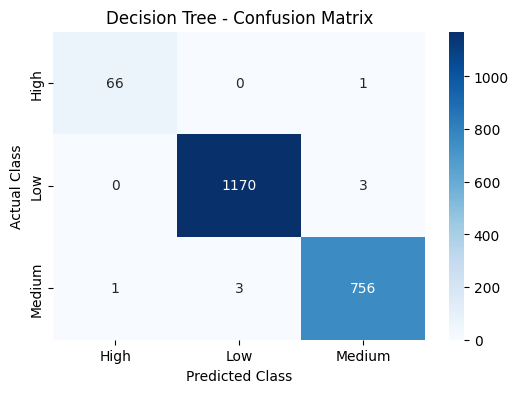

In [25]:


# 1. Accuracy
print("Accuracy:", round(accuracy_score(y_test, y_pred_dt), 4))

# 2. Precision
print("Precision (Macro):", round(
    precision_score(y_test, y_pred_dt, average="macro", zero_division=0), 4
))

# 3. Recall
print("Recall (Macro):", round(
    recall_score(y_test, y_pred_dt, average="macro", zero_division=0), 4
))

# 4. F1-score
print("F1-Score (Macro):", round(
    f1_score(y_test, y_pred_dt, average="macro", zero_division=0), 4
))

# 5. Classification Report
print("\nClassification Report:\n")
print(classification_report(
    y_test,
    y_pred_dt,
    target_names=label_encoder.classes_,
    zero_division=0
))

# 6. Confusion Matrix
cm = confusion_matrix(y_test, y_pred_dt)

print("Confusion Matrix:\n", cm)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Decision Tree - Confusion Matrix")
plt.show()

In [26]:


# Initialize the model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
y_pred_rf = rf_model.predict(X_test)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


Random Forest Evaluation
-----------------------------------
Accuracy: 0.9705
Precision (Macro): 0.9776
Recall (Macro): 0.7974
F1-Score (Macro): 0.8476

Classification Report:

              precision    recall  f1-score   support

        High       1.00      0.42      0.59        67
         Low       0.98      1.00      0.99      1173
      Medium       0.95      0.97      0.96       760

    accuracy                           0.97      2000
   macro avg       0.98      0.80      0.85      2000
weighted avg       0.97      0.97      0.97      2000

Confusion Matrix:
 [[  28    0   39]
 [   0 1172    1]
 [   0   19  741]]


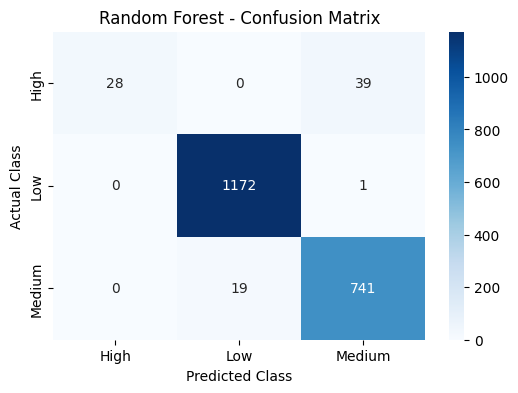

In [27]:

# Print evaluation metrics
print("Random Forest Evaluation")
print("-" * 35)
print("Accuracy:", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision (Macro):", round(
    precision_score(y_test, y_pred_rf, average="macro", zero_division=0), 4
))
print("Recall (Macro):", round(
    recall_score(y_test, y_pred_rf, average="macro", zero_division=0), 4
))
print("F1-Score (Macro):", round(
    f1_score(y_test, y_pred_rf, average="macro", zero_division=0), 4
))

print("\nClassification Report:\n")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=label_encoder.classes_,
    zero_division=0
))

# Confusion matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)

print("Confusion Matrix:\n", cm_rf)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Random Forest - Confusion Matrix")
plt.show()

In [12]:

# Initialize model
gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Train model
gb_model.fit(X_train, y_train)

# Predict
y_pred_gb = gb_model.predict(X_test)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


In [13]:

print("Gradient Boosting Evaluation")
print("-" * 35)
print("Accuracy:", round(accuracy_score(y_test, y_pred_gb), 4))
print("Precision (Macro):", round(
    precision_score(y_test, y_pred_gb, average="macro", zero_division=0), 4
))
print("Recall (Macro):", round(
    recall_score(y_test, y_pred_gb, average="macro", zero_division=0), 4
))
print("F1-Score (Macro):", round(
    f1_score(y_test, y_pred_gb, average="macro", zero_division=0), 4
))

print("\nClassification Report:\n")
print(classification_report(
    y_test,
    y_pred_gb,
    target_names=label_encoder.classes_,
    zero_division=0
))

cm_gb = confusion_matrix(y_test, y_pred_gb)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_gb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Gradient Boosting - Confusion Matrix")
plt.show()

Gradient Boosting Evaluation
-----------------------------------


NameError: name 'accuracy_score' is not defined

In [30]:

models = {
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "Gradient Boosting": y_pred_gb
}

results = []

for name, y_pred in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (Macro)": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "F1-Score (Macro)": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )
    })

comparison_df = pd.DataFrame(results)

print("Model Performance Comparison")
display(comparison_df.round(4))

Model Performance Comparison


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro)
0,Decision Tree,0.9960,0.9924,0.9924,0.9924
1,Random Forest,0.9705,0.9776,0.7974,0.8476
2,Gradient Boosting,0.9970,0.9974,0.9701,0.9831


Gradient Boosting Training Accuracy: 0.9998
Gradient Boosting Testing Accuracy: 0.997


,Feature,Importance
1,Soil_Moisture,0.242035
21,Crop_Growth_Stage_Flowering,0.120871
6,Rainfall_mm,0.116939
4,Temperature_C,0.114019
8,Wind_Speed_kmh,0.106522
24,Crop_Growth_Stage_Vegetative,0.077179
36,Mulching_Used_No,0.062218
23,Crop_Growth_Stage_Sowing,0.056478
22,Crop_Growth_Stage_Harvest,0.052519
37,Mulching_Used_Yes,0.047973


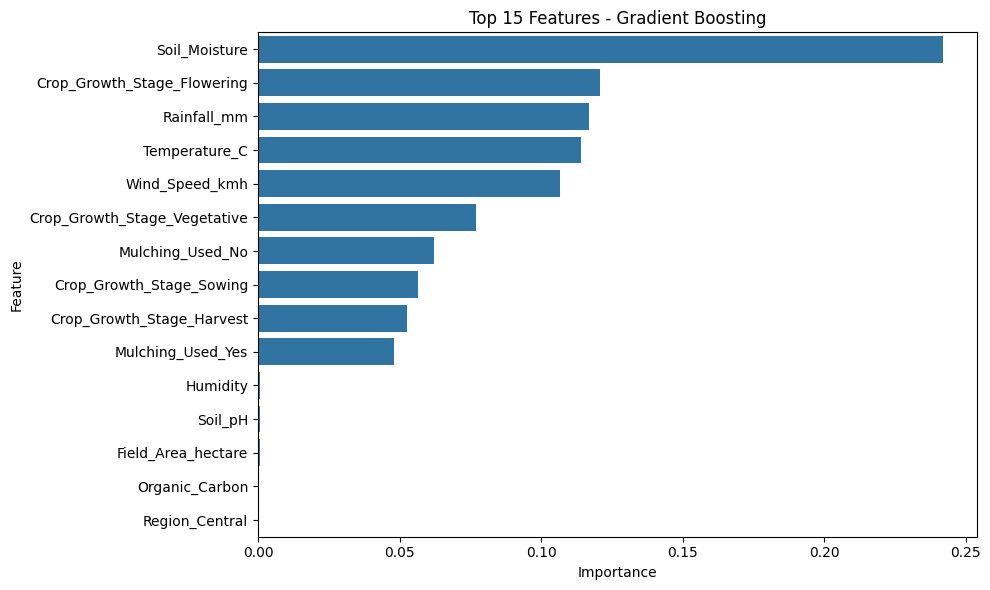

In [38]:


# Compare training and testing performance
print("Gradient Boosting Training Accuracy:",
      round(accuracy_score(y_train, gb_model.predict(X_train)), 4))

print("Gradient Boosting Testing Accuracy:",
      round(accuracy_score(y_test, y_pred_gb), 4))

# Examine feature importance
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": gb_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df.head(15))

plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)
plt.title("Top 15 Features - Gradient Boosting")
plt.tight_layout()
plt.show()

In [3]:
!pip install -q skl2onnx onnx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 317.2/317.2 kB 7.4 MB/s eta 0:00:00ta 0:00:01


In [15]:
from skl2onnx import convert_sklearn
from skl2onnx.common.data_types import FloatTensorType

onnx_model = convert_sklearn(
    gb_model,
    initial_types=[
        ("input", FloatTensorType([None, X_train.shape[1]]))
    ]
)

with open("best_gboost_model.onnx", "wb") as f:
    f.write(onnx_model.SerializeToString())

print("ONNX export completed!")

ONNX export completed!


In [16]:
import onnx

onnx.checker.check_model(onnx_model)
print("ONNX model validation successful!")

ONNX model validation successful!


In [18]:
import json

metadata = {
    "feature_columns": X_train.columns.tolist(),
    "classes": label_encoder.classes_.tolist()
}

with open("model_metadata.json", "w") as file:
    json.dump(metadata, file, indent=4)

print("Metadata saved successfully!")

Metadata saved successfully!


In [19]:
import os

print(os.path.exists("best_gboost_model.onnx"))
print(os.path.exists("model_metadata.json"))
print(os.listdir("/kaggle/working"))

True
True
['best_gboost_model.onnx', 'model_metadata.json', '.virtual_documents']
